# Tools - flow in networks I
This notebook presents some tools related to (laminar) flow in a graph (network):
- solving flow problem without boundary condition
- computing equivalent resistance between any pair of nodes
- leverage score of edges

*Note. Presented tool works on `networkx.Graph` objects. A `KGraph` object `kg` can be defined from a `networkx.Graph` graph `g` with `kg = kn.from_networkx(g)`.*

## Reference
- Daniel A. Spielman (2025), Spectral and Algebraic Graph Theory, Draft published by the author on the web, http://cs-www.cs.yale.edu/homes/spielman/sagt


## Flow in a network - Background

Consider an undirected weighted graph $G=(V, E)$ with $\omega(e)>0$ the weight on the edge $e\in E$. Note $V=\{v_1, \ldots, v_n\}$ the set of nodes a(vertices) and $\omega_{ij} = \omega(e)$ if $e = \{v_i, v_j\} \in E$ and $\omega_{ij}=0$ otherwise. Note that an edge $\{v_i, v_j\}$ in $E$ can be noted $v_i\sim v_j$ or even $ij$.

### Local flow equation
Let $p\in\mathbb{R}^n$, $p_i=p(v_i)$ a potential at node $v_i$, and let $q_{ij} = q(v_i, v_j)$ a flux going from node $v_i$ to node $v_j$ through the edge $\{v_i, v_j\}$ ($q_{ij} = 0$ if $\{v_i,v_j\} \not \in E$). 

Locally, for each edge $\{v_i,v_j\}$, we consider the equation
- $q(v_i, v_j) = -\omega_{ij} (p(v_j) - p(v_i))$

where the flux is proportional to the difference of potential between the two end nodes. Note that $p(v_j) < p(v_i)$ implies a flux $q(v_i, v_j)>0$, i.e. a flux going from $v_i$ to $v_j$, that is from the node of higher potential to the node of lower potential.

**Remark.** This local equation is the Ohm's law in electricity or the Darcy's law in hydrology; the proportional factors ($\omega_{ij}$) are conductance, which accounts for the "geometry" of the edges.

### Flow equations in the entire network
Let $q_i^{\textit{ext}} = q^{\textit{ext}}(v_i)$ the flux entering into the network (graph) at node $v_i$ (from the exterior). Then at the equilibrum (Kirchoff's law), we have the equations
- $-q^{\textit{ext}}(v_i) + \sum_{j : v_i\sim v_j} q(v_i, v_j) = 0$, for $i=1, \ldots, n$,

i.e. the sum of fluxes going out of the node $v_i$ is equal to zero. Hence, with the previous local equation, 
- $-q_i^{\textit{ext}} + \sum_{j : v_i\sim v_j} \omega_{ij} (p_i - p_j) = 0$, for $i=1, \ldots, n$,

which is written in matrix form
- $L p = q^{\textit{ext}}$

where $L$ is the (weighted) Laplacian matrix of the graph $G$, i.e. $L = D - A$, with
$A$ the (weighted) adjacency matrix defined as $A(i, j) = \omega_{ij}$ if $v_i\sim v_j$ and $A(i, j) = 0$ otherwise, and $D = \operatorname{diag}(d_{\omega}(1), \ldots, d_{\omega}(n))$, with $d_{\omega}(i) = \sum_{j : v_i \sim v_j}\omega_{ij}$ the (weighted) degree of the node $v_i$.

The Laplacian matrix $L$ is symmetric positive semi-definite, and for a connected graph $G$ (i.e. with one connected component), its eigen values are $0 = \lambda_1 < \lambda_2\leq \cdots \leq \lambda_n$, and the eigen space for the eigen value $\lambda_1=0$ is $\operatorname{Ker}(L)= \langle (1, \ldots, 1)^\top\rangle$. As a consequence, $\operatorname{Im}(L) = \operatorname{Ker}(L)^\bot = \{q : \sum_i q_i = 0\}$. Considering an orthonormal basis $\{u_1,\ldots, u_n\}$ of $\mathbb{R}^n$ composed of eigen vectors of $L$, with $L u_i = \lambda_i u_i$, the matrix
- $L^{+} = \sum_{i=2}^n \frac{1}{\lambda_i} u_i\cdot u_i^\top$ 

is the pseudo-inverse of $L$ (Moore-Penrose inverse), more precisely, $L^{+}\cdot L = L\cdot L^{+} = \sum_{i=2}^n u_i\cdot u_i^\top$ is the orthogonal projector onto $\operatorname{Im}(L)$.

Hence, providing $q^{\textit{ext}}$ such that $\sum_i q_i^{\textit{ext}} = 0$ (i.e. $q^{\textit{ext}} \in \operatorname{Im}(L)$), the solution of $L p = q^{\textit{ext}}$ is given (up to a constant) by
- $p = L^{+}\cdot q^{\textit{ext}}$

**Remark**. Solving the equation $L p = q^{\textit{ext}}$, for given exterior flux vector, allows to get the potential at the graph nodes and then the flux in any edge by using the local equation (Darcy's or Ohm's law).

### Equivalent conductance
Consider a pair of node $a, b\in V$ and an input flux of $1$ (coming into the network) at node $a$ and an output flux of $1$ (going out the network) at node $b$, i.e. the exterior flux vector $q^{\textit{ext}}=\delta_a - \delta_b$, with $\delta_a(v)=1$ if $v=a$ and $\delta_a(v)=0$ otherwise.

The solution of the equation $L p = q^{\textit{ext}}$ gives the potential at each node of the network, and considering the simplified network with only the two nodes $a, b$ and one edge between them, the local equation, i.e. the relation
- $1 = q(a, b) = - \omega^{\textit{eq}}(a, b) (p(b) - p(a))$

allows to get the equivalent conductance between $a$ and $b$. Then
- $\omega^{\textit{eq}}(a, b) = \frac{1}{p(a)-p(b)}$.

As $p = L^{+}\cdot q^{\textit{ext}}= L^{+}\cdot (\delta_a - \delta_b)$, it follows $p(a) - p(b) = {q^{\textit{ext}}}^\top \cdot L^{+}\cdot q^{\textit{ext}} = (\delta_a - \delta_b)^\top \cdot L^{+}\cdot (\delta_a - \delta_b)$.

**Note.** The equivalent resistance is $R^{\textit{eq}} = 1/\omega^{\textit{eq}}$.

### Leverage score (see Spielman)
The leverage score of an edge $e$ is defined as
- $\ell(e) = \omega(e) \cdot R^{\textit{eq}}(e)$. 

Properties: we have
- $\ell(e) \leq 1$ for all $e\in E$ (edges)
- $\sum_{e\in E} l(e) =  \vert V\vert - 1$ (number of nodes minus one)

The leverage score gives the importance of an edge in the network. Indeed, if removing an edge $e$ disconnects the graph, then, all the flux goes through that edge and $\omega^{\textit{eq}}(e) = \omega(e)$ i.e. $l(e) = 1$.


In [1]:
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
import scipy
import time

In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
# import pyvista as pv

# # Choose backend for pyvista with jupyter
# # ---------------------------------------
# pv.set_jupyter_backend('static') # static plots
# # pv.set_jupyter_backend('trame')  # 3D-interactive plots

# # Notes:
# # -> ignored if run in a standard python shell
# # -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.6


## Illustration on a small graph in 2D
A 2D example - a graph generated from a Delaunay triangulation of points.

In [5]:
# Options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'linewidths'  : 1,           # node border width       
    'edgecolors'  : 'gray',      # node border color
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

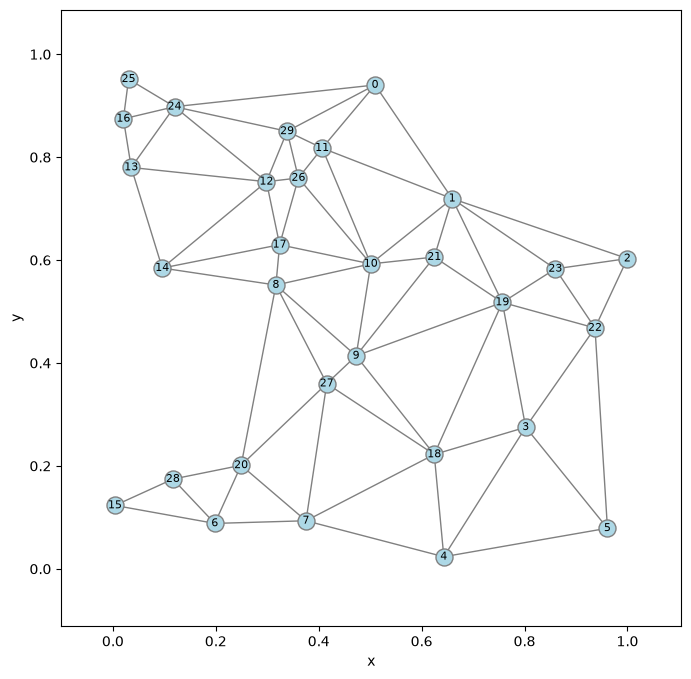

In [6]:
# Number of points and seed
npoints = 30
seed = 35306

# Generate random points uniformly in [0, 1] x [0, 1]
np.random.seed(seed)
points = np.random.random(size=(npoints, 2))

# Generate 2D graph from Delaunay triangulation of the points,
# edges whose length are less (resp. greater) than a mininmal (resp. maximal) valuse are removed
g = kn.misc.graph_from_delaunay_tri(points,min_edge_len=0.01, max_edge_len=0.4)

# Keep the largest connected component
g = kn.utils.get_list_of_connected_components(g, order='descending', renumbering_nodes=True)[0]

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

- Add a node with a string as label to check that the developed algorithms work property

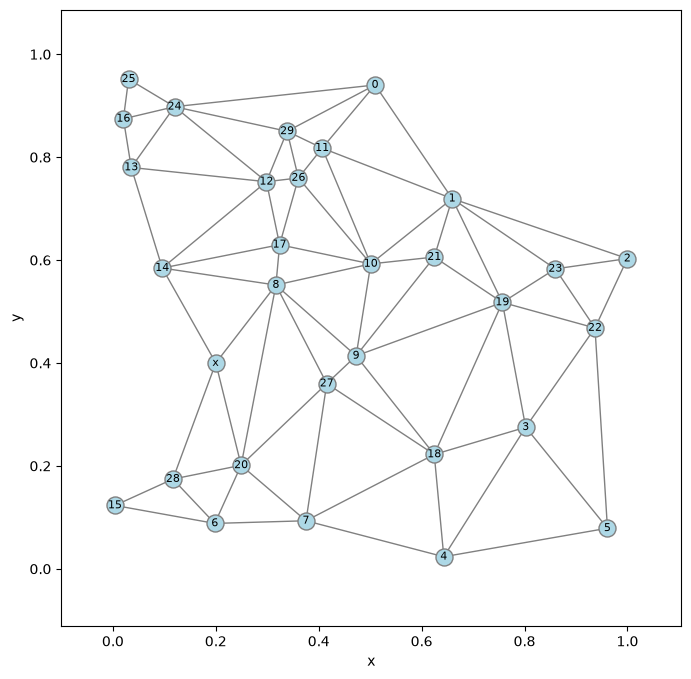

In [7]:
# Add a node with label 'x' and some edges
g.add_node('x')
g.nodes['x']['pos'] = np.array([0.2, 0.4])
g.add_edges_from([('x', i) for i in [8, 14, 28, 20]])

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

### Set edge weight (conductance $\omega$)

In [8]:
# Set edge weight (w) (conductance)
# ---------------------------------
# # Uniform (constant)
# w = {e: 1.0 for e in g.edges()} # unweigted graph (specifying argument edge_weight=None in the functions below)

# # Set random conductance on edges - U([0, 1])
# np.random.seed(1211)
# w_arr = np.random.rand(len(g.edges()))
# w = {e: wi for e, wi in zip(g.edges(), w_arr)}

# # Set random conductance on edges - lognormal, log weight ~ N(m, s^2)
# np.random.seed(353)
# m = 0.0
# s = 1.0
# w_arr = np.exp(scipy.stats.norm(loc=m, scale=s).rvs(g.number_of_edges())) # random values in log-normal distribution
# w = {e: wi for e, wi in zip(g.edges(), w_arr)}

# Inverse of edge length
w = kn.utils.get_edge_length_dict(g, 'pos', exponent=-1)
# w = {e: 1.0/np.sqrt(np.sum((np.asarray(g.nodes[e[0]]['pos']) - np.asarray(g.nodes[e[1]]['pos']))**2)) for e in g.edges()} # Equiv.

nx.set_edge_attributes(g, w, 'w')


### Plot conductances

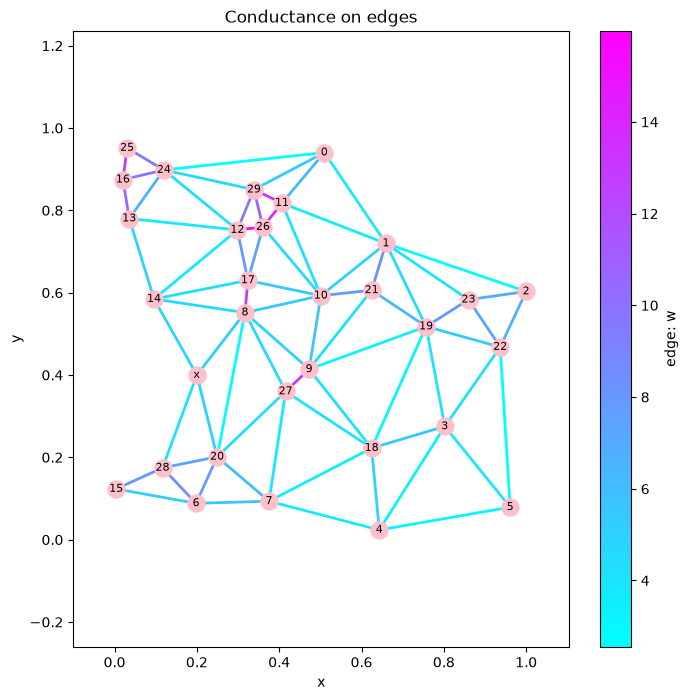

In [9]:
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='cool',
    **options)
plt.title('Conductance on edges')
plt.show()

### Plot conductances - edge width proportional to conductance

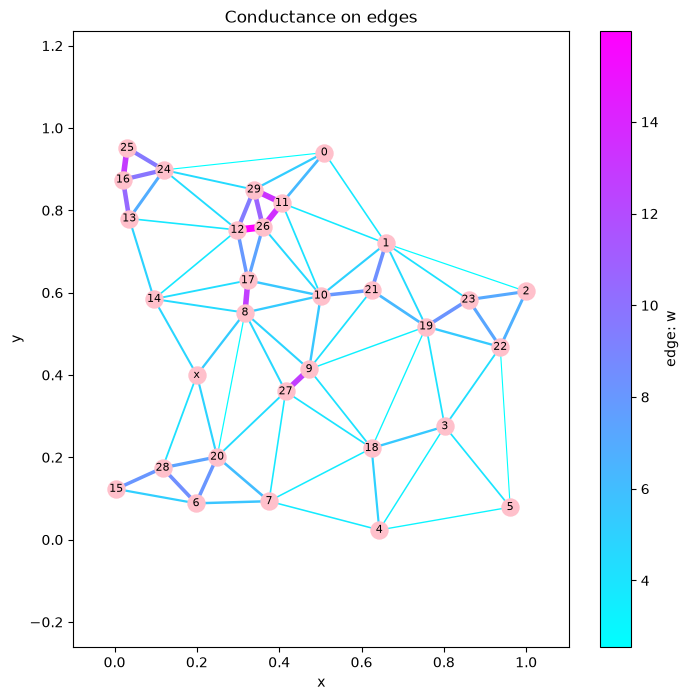

In [10]:
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Edge width for 'w' and 'q'
w = np.asarray(list(nx.get_edge_attributes(g, 'w').values()))
w_width_max = 5
w_width = w/w.max() * w_width_max

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='cool',
    width = w_width, # set edge  width
    **options)
plt.title('Conductance on edges')
plt.show()

### Compute the Laplacian matrix

In [11]:
# Laplacian matrix in sparse (CSR) format
g_lap = nx.laplacian_matrix(g, weight='w')
g_lap

<Compressed Sparse Row sparse array of dtype 'float64'
	with 179 stored elements and shape (31, 31)>

### Laplacian matrix expressed with incidence matrix
On a graph $G=(V, E)$, with 
- $B$ the incidence matrix, of dimension $\vert V\vert \times \vert E\vert$, with one $1$ and one $-1$ on each column according to the edge (arbitrary direction),
- $W$ the diagonal matrix of edge weights
- $L$ the Laplacian matrix accounting for edge weigths

we have
- $L = B\cdot W\cdot B^\top$

In [12]:
# Incidence matrix |V| x |E|
incidence_mat = nx.incidence_matrix(g, oriented=True) # csr matrix
# incidence_mat.indptr, incidence_mat.indices, incidence_mat.data
# incidence_mat.toarray()

# Diagonal matrix of edge weight
w = np.asarray(list(nx.get_edge_attributes(g, 'w').values()))
edge_w_diag_mat = scipy.sparse.diags(w) # csr matrix (diagonal matrix)
# edge_w_diag_mat.toarray()

diff_mat = incidence_mat @ edge_w_diag_mat @ incidence_mat.T - g_lap
np.allclose(diff_mat.toarray(), 0.0)

True

### Compute the eigen values and eigen vectors of the Laplacian matrix

In [13]:
# Compute (first) eigen values and eigen vectors of the Laplacian matrix,
# used further for (approximation) of the pseudo-inverse of the Laplacian matrix
k = None # maximum number of eigen values and eigen vectors to compute (None: all)

if k is None:
    print('Compute all eigen values and eigen vectors of the Laplacian matrix')
else:
    print(f'Compute the first {k} (at max.) eigen values and eigen vectors of the Laplacian matrix')

t1 = time.time()
lap_eigval, lap_eigvec = kn.tools.laplacian_eigs(g, edge_weight='w', k=k)
t2 = time.time()

print(f'Elapsed time: {t2-t1:.2f} sec')

Compute all eigen values and eigen vectors of the Laplacian matrix
Elapsed time: 0.01 sec


In [14]:
# Note: the eigen values can be computed as follows:
lap_eigval2 = nx.laplacian_spectrum(g, weight='w')
np.allclose(lap_eigval, lap_eigval2[:len(lap_eigval)])

True

In [15]:
lap_eigval

array([-1.16457118e-14,  2.04508623e+00,  2.72926201e+00,  5.75965629e+00,
        7.19917479e+00,  9.73285743e+00,  1.14871973e+01,  1.43394715e+01,
        1.63780170e+01,  1.81903572e+01,  1.97258695e+01,  2.09887949e+01,
        2.22900943e+01,  2.64531466e+01,  2.65812373e+01,  2.79495692e+01,
        3.02142892e+01,  3.21947082e+01,  3.38136128e+01,  3.76339526e+01,
        3.80598386e+01,  3.98610438e+01,  4.15847806e+01,  4.26530745e+01,
        4.46360960e+01,  4.54795742e+01,  4.71801273e+01,  4.91686560e+01,
        5.46227515e+01,  5.88528307e+01,  6.99656262e+01])

### Compute the pseudo-inverse of the Laplacian matrix (or approximation)

In [16]:
# Compute the pseudo-inverse of Laplacian matrix
# (eigen values and eigen vectors can be passed as keyword arguments if they are already computed)
g_lap_pinv = kn.tools.laplacian_pseudo_inverse(g, eigval=lap_eigval, eigvec=lap_eigvec)
# OR:
# g_lap_pinv = kn.tools.laplacian_pseudo_inverse(g, edge_weight='w', k=k)
# 
# -> g_lap_pinv is an array of shape (n. n), with n = g.number_of_nodes()


### Set correspondance between node label and node index

In [17]:
# Set dictionary to convert node label to node index
node_label2index = kn.utils.get_node_label2index_dict(g)
# node_label2index = {u:i for i, u in enumerate(G.nodes())} # equiv.

# Set dictionary to convert node index to node label
node_index2label = kn.utils.get_node_index2label_dict(g)
#node_index2label = {i:u for i, u in enumerate(G.nodes())} # equiv.

## Flow in the network (no boundary condition)


### Source term - flux of $q=1$ entering at one inlet node and exiting at one outlet node
The source term $q^{\textit{ext}}$, is the vector of entering fluxes, of length $\vert V\vert$ (number of graph nodes), with $1$ at the inlet node, $-1$ at the outlet node and $0$ at other nodes.

In [18]:
# Set inlet and outlet (flux)
node_inlet = 'x'
node_outlet = 3

### Solve flow equation - find node potential
Solve $L p = q^{\textit{ext}}$, with $q^{\textit{ext}}$ the external entering flux at nodes (source term).


In [19]:
# Alternative 1
# -------------
# Set source term (inject flux of 1 at inlet node and "pump" flux of -1 at outlet node)
qext = np.zeros(g.number_of_nodes())
qext[node_label2index[node_inlet]] = 1.0
qext[node_label2index[node_outlet]] = -1.0

# Solve L p = qext, p potential at nodes
p = g_lap_pinv @ qext
# # Or:
# p = lap_eigvec[:,1:] @ (1.0/lap_eigval[1:] * (lap_eigvec[:,1:].T @ qext))
# -> p: array of potential at nodes

# Set dictionary of node potential
# (dictionary with node label as key and potential at node as value)
p_nodes_dict_1 = {u: p[node_label2index[u]] for u in g.nodes()}

In [20]:
# Alternative 2 (for this specific qext)
# -------------
# Get node index of inlet node and outlet node
i0, i1 = node_label2index[node_inlet], node_label2index[node_outlet]

# Solve L p = qext, p potential at nodes
p = lap_eigvec[:, 1:] @ (1.0/lap_eigval[1:] * (lap_eigvec[i0, 1:] - lap_eigvec[i1, 1:]))

# Set dictionary of node potential
# (dictionary with node label as key and potential at node as value)
p_nodes_dict_2 = {u: p[node_label2index[u]] for u in g.nodes()}

In [21]:
# Alternative 3
# -------------
# Set source term (inject flux of 1 at inlet node and "pump" flux of -1 at outlet node)
q_nodes_dict = {k:0.0 for k in g.nodes()} # flux at nodes
q_nodes_dict[node_inlet] = 1.0  # flux at inlet node
q_nodes_dict[node_outlet] = -1.0 # flux at outlet node

# Solve L p = qext, p potential at nodes
p_nodes_dict_3 = kn.tools.solve_flow_without_bc(g, q_nodes_dict=q_nodes_dict, eigval=lap_eigval, eigvec=lap_eigvec) # using pre-computed eigen valuse and eigen vector of the Laplacian matrix
# p_nodes_dict_3 = kn.tools.solve_flow_without_bc(g, q_nodes_dict=q_nodes_dict, edge_weight='w', k=None)
# -> p_nodes_dict_3: dictionary with node label as key and potential at node as value

In [22]:
# Same results ?
p1 = np.asarray([p_nodes_dict_1[u] for u in g.nodes()]) # array of potential at nodes
p2 = np.asarray([p_nodes_dict_2[u] for u in g.nodes()])
p3 = np.asarray([p_nodes_dict_3[u] for u in g.nodes()])

print(f'All methods give same results ? {np.all((np.allclose(p1, p2), np.allclose(p1, p3)))}')


All methods give same results ? True


In [23]:
p_nodes_dict = p_nodes_dict_1 # or p_nodes_dict_2 or p_nodes_dict_3

### Compute equivalent conductance between inlet and outlet nodes

In [24]:
# Get potential difference between inlet and outlet nodes
pdiff_in_out = p_nodes_dict[node_inlet] - p_nodes_dict[node_outlet]
# pdiff_in_out = qext @ p # Equiv.

# Compute equivalent conductance / equivalent resistance between inlet and outlet nodes
weq = 1.0 / pdiff_in_out # equivalent conductance
req = 1.0 / weq  # equivalent resistance
print(f'Equivalent conductance: {weq:.4g}')
print(f'Equivalent resistance : {req:.4g}')

Equivalent conductance: 5.792
Equivalent resistance : 0.1727


*Note: the equivalent conductance between any two nodes can be computed in different ways (in particular with the function `kn.tools.equivalent_conductance`), see at the end of this notebook.*

### Compute flow along edges

In [25]:
# Set node potential as node attribute in graph `g`
nx.set_node_attributes(g, p_nodes_dict, 'potential')

In [26]:
# Absolute flows along edges
# --------------------------
# Compute absolute flows along edges
edge_abs_flow_dict = kn.tools.compute_abs_flow_along_edges(g, edge_weight='w', node_potential='potential')

# Set absolute flow as edge attribute in graph `g`
nx.set_edge_attributes(g, edge_abs_flow_dict, 'q_abs')

# Flows along edges - directed graph
# ----------------------------------
g_dir = kn.tools.compute_directed_graph_of_flow(g, edge_weight='w', node_potential='potential', edge_flow='q')
# -> directed graph with flow as edge attributes - only the edges with positive (or zero) flow are kept

### Plot result (1) - undirected graph
Plot node potential and absolute edge flow.

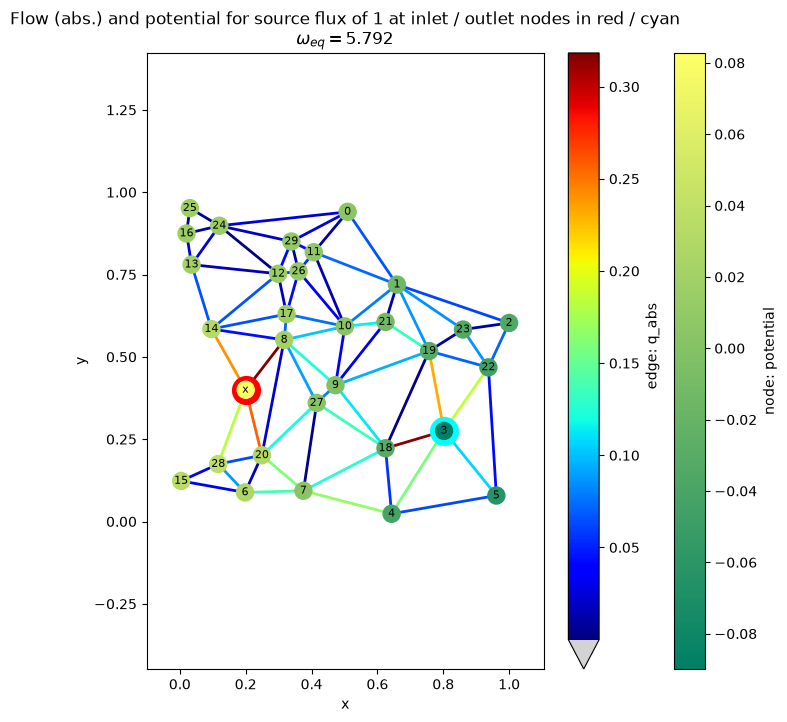

In [27]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10


# Plot - potential on nodes and absolute flow on edges
# ----------------------------------------------------
plt.figure(figsize=(8, 8))

kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'extend':'min'},
    **options)

# ... highlight inlet / outlet nodes
plt.scatter(*g.nodes[node_inlet]['pos'],  marker='o', s=400, color='red',  alpha=1)
plt.scatter(*g.nodes[node_outlet]['pos'], marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flow (abs.) and potential for source flux of 1 at inlet / outlet nodes in red / cyan\n'+ r'$\omega_{eq}=$' + f'{weq:.4g}')

plt.show()


### Plot results (2) - directed graph

Plot node potential and oriented edge flow.

*Note. With directed graph, the color bar can not be displayed, because the function `nx.draw_networkx_edges` does not return any "mappable" required for plotting color bar. To display the color bar, one can first employ the undirected graph with absolute values of flow on edges, and then utilize the directed graph to show the oriented edges (see below).*

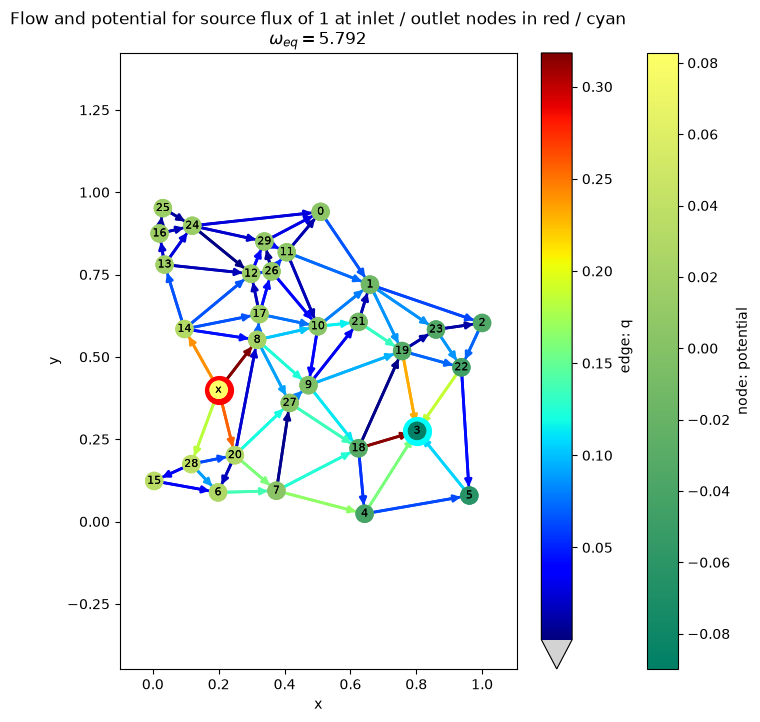

In [28]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10


# Plot - potential on nodes and oriented flow on edges
# ----------------------------------------------------
plt.figure(figsize=(8, 8))

# ... display unoriented edge with color bar
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'label':'edge: q', 'extend':'min'},
    **options)

# ... display the oriented edges without color bar
kn.view.plot_graph2d(
    g_dir, 
    node_attr='potential', cmap=cmap, 
    show_node_colorbar=False, # already displayed with plot of g_sol above
    edge_attr='q', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    show_edge_colorbar=False, # already displayed with plot of g_sol above 
                              # note: with directed graph, color bar can not be displayed
                              # (function 'nx.draw_networkx_edges' not mappable)
    **options)

# ... highlight inlet / outlet nodes
plt.scatter(*g.nodes[node_inlet]['pos'],  marker='o', s=400, color='red',  alpha=1)
plt.scatter(*g.nodes[node_outlet]['pos'], marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flow and potential for source flux of 1 at inlet / outlet nodes in red / cyan\n'+ r'$\omega_{eq}=$' + f'{weq:.4g}')

plt.show()


### Plot results (3) - directed graph - custom
Plot node potential and oriented edge flow ; set edge width according to values and add edge labels.

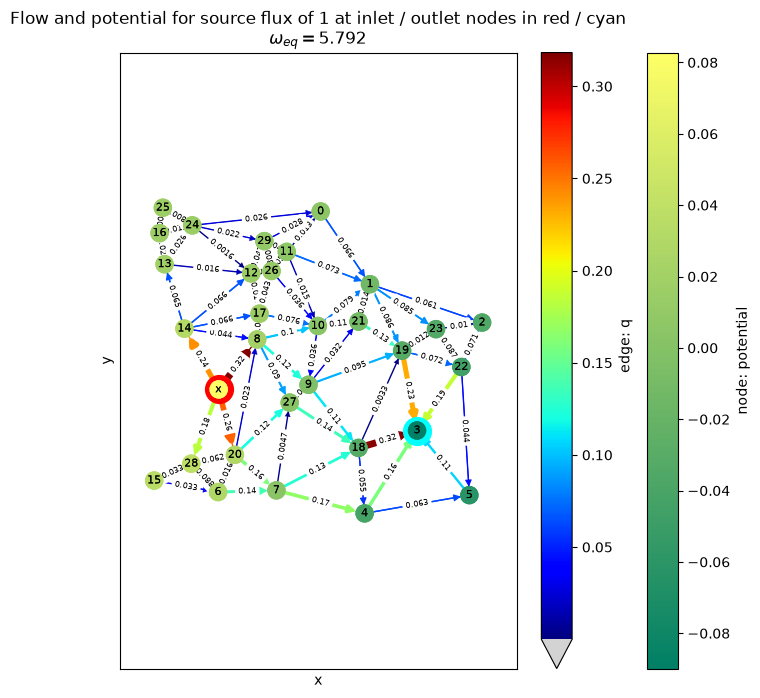

In [29]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    # 'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Edge width according to flow ('q') intensity
q = np.abs(np.asarray(list(nx.get_edge_attributes(g_dir, 'q').values())))
q_width_max = 5
q_width = q/q.max() * q_width_max

# Node position (used below to draw edge labels)
pos = nx.get_node_attributes(g, 'pos')

# Color map for node attribute (potential)
cmap = 'summer'

# Color map for edge attribute (flow)
edge_cmap = plt.get_cmap('jet')
edge_cmap.set_under('lightgray') # color for value below lower limit 'edge_vmin' (if specified) / distinguish zero-flow
edge_vmin = 1.e-10


# Plot - potential on nodes and oriented flow on edges
# ----------------------------------------------------
plt.figure(figsize=(8, 8))

# ... display unoriented edge with color bar
kn.view.plot_graph2d(
    g, 
    node_attr='potential', cmap=cmap,
    edge_attr='q_abs', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    options_edge_colorbar={'label':'edge: q', 'extend':'min'},
    **options)

# ... display the oriented edges without color bar
kn.view.plot_graph2d(
    g_dir, 
    node_attr='potential', cmap=cmap, 
    show_node_colorbar=False, # already displayed with plot of g_sol above
    edge_attr='q', edge_cmap=edge_cmap, edge_vmin=edge_vmin,
    show_edge_colorbar=False, # already displayed with plot of g_sol above 
                              # note: with oriented graph, color bar can not be displayed
                              # (function 'nx.draw_networkx_edges' not mappable)
    width = q_width, # set edge  width
    **options)

# ...add edge labels
edge_labels = {k:f'{v:.2g}' for k, v in nx.get_edge_attributes(g, 'q_abs').items()}
nx.draw_networkx_edge_labels(g, pos=pos, edge_labels=edge_labels, font_color='black', font_size=6)

# ... highlight inlet / outlet nodes
plt.scatter(*g.nodes[node_inlet]['pos'],  marker='o', s=400, color='red',  alpha=1)
plt.scatter(*g.nodes[node_outlet]['pos'], marker='o', s=400, color='cyan', alpha=1)

plt.title(f'Flow and potential for source flux of 1 at inlet / outlet nodes in red / cyan\n'+ r'$\omega_{eq}=$' + f'{weq:.4g}')

plt.show()


## Illustration of leverage scores

In [30]:
# Leverage score
# --------------
# Compute equivalent conductance on each edge
weq_arr = kn.tools.equivalent_conductance(g, list(g.edges()), edge_weight='w')

w = nx.get_edge_attributes(g, 'w')
w_arr = np.asarray(list(w.values()))

# Set leverage score as edge attribute
leverage_score_arr = w_arr * 1.0/weq_arr
leverage_score = {e: li for e, li in zip(g.edges(), leverage_score_arr)} 
nx.set_edge_attributes(g, leverage_score, 'leverage_score')


In [31]:
print(f'All leverage scores less than or equal to one ? {np.all(leverage_score_arr <= 1)}')
print(f'Sum of all leverage scores = {np.sum(leverage_score_arr):.4g}')
print(f'Number of nodes = {g.number_of_nodes()}')
print(f'Sum of all leverage scores = Number of nodes minus one ? {np.isclose(np.sum(leverage_score_arr), g.number_of_nodes()-1)}')

All leverage scores less than or equal to one ? True
Sum of all leverage scores = 30
Number of nodes = 31
Sum of all leverage scores = Number of nodes minus one ? True


### Plot - conductance and leverage score on edges

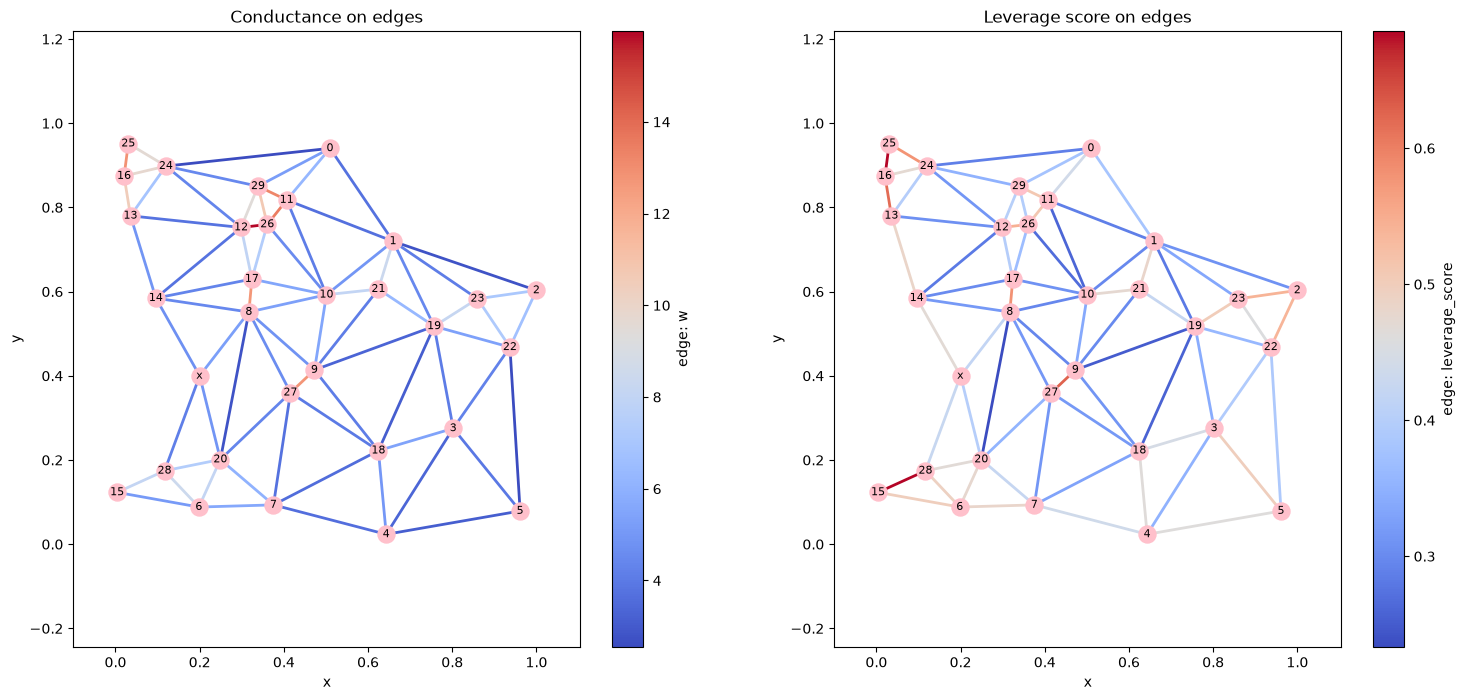

In [32]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Plot
# ====
plt.subplots(1,2, figsize=(18, 8))

# Plot conductance on edges
# -------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='coolwarm',
    **options)
plt.title('Conductance on edges')

# Plot leverage score on edges
# ----------------------------
plt.subplot(1,2,2)
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='leverage_score', edge_cmap='coolwarm',
    **options)
plt.title('Leverage score on edges')

plt.show()


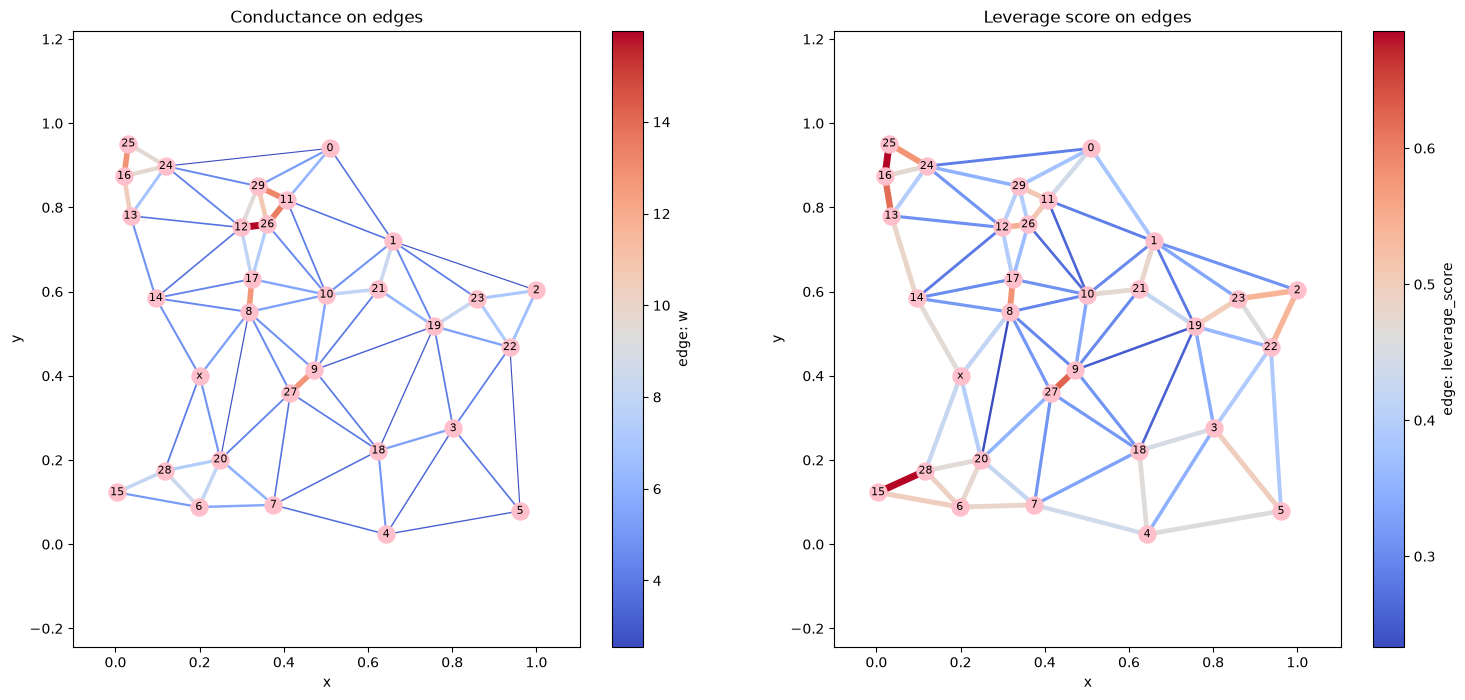

In [33]:
# Common options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'node_color'  : 'pink',      # node color (default - if no attribute is specified or for nan values)
    # 'width'       : 2,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,
    'axis_equal'  : True
}

# Edge width for 'w' and 'leverage_score'
w = np.asarray(list(nx.get_edge_attributes(g, 'w').values()))
w_width_max = 5
w_width = w/w.max() * w_width_max

leverage_score = np.abs(np.asarray(list(nx.get_edge_attributes(g, 'leverage_score').values())))
leverage_score_width_max = 5
leverage_score_width = leverage_score/leverage_score.max() * leverage_score_width_max

# Plot
# ====
plt.subplots(1,2, figsize=(18, 8))

# Plot conductance on edges
# -------------------------
plt.subplot(1,2,1)
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='coolwarm',
    width = w_width, # set edge  width
    **options)
plt.title('Conductance on edges')

# Plot leverage score on edges
# ----------------------------
plt.subplot(1,2,2)
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='leverage_score', edge_cmap='coolwarm',
    width = leverage_score_width, # set edge width
    **options)
plt.title('Leverage score on edges')

plt.show()


## Alternatives to compute equivalent resistance between any two nodes

Solving flow equations with boundary conditions (used in method 3 below) is described in notebook `H2-Flow-in-networks-II.ipynb`. 

*Note that the equivalent conductance is the inverse of the equivalent resistance.*

In [36]:
# Alternatives to compute equivalent resistance between any two nodes
# -------------------------------------------------------------------
node_inlet_label = 'x'
node_outlet_label = 3

# Method 1 : Use the dedicated function `kn.tools.equivalent_conductance`
# --------
Weq_1_arr = kn.tools.equivalent_conductance(g, [[node_inlet_label, node_outlet_label]], eigval=lap_eigval, eigvec=lap_eigvec) # using pre-computed eigen values and eigen vectors
# # Or equivalently:
# Weq_1_arr = kn.tools.equivalent_conductance(g, [[node_inlet_label, node_outlet_label]], edge_weight='w') # not using pre-computed eigen values and eigen vectors
Req_1 = 1.0 / Weq_1_arr[0]

# Method 2 : Use pre-computed eigen values and eigen vectors of the Laplacian matrix
# --------
# Set dictionary to convert node label to node index
node_label2index = kn.utils.get_node_label2index_dict(g)
node_inlet_index = node_label2index[node_inlet_label]
node_outlet_index = node_label2index[node_outlet_label]

Req_2 = np.sum(1.0/lap_eigval[1:] * (lap_eigvec[node_inlet_index, 1:] - lap_eigvec[node_outlet_index, 1:])**2)
# # Or equivalently:
# qext = np.zeros(g.number_of_nodes())
# qext[node_inlet_index] = 1.0
# qext[node_outlet_index] = -1.0
# p = lap_eigvec[:, 1:] @ (1.0/lap_eigval[1:] * (lap_eigvec[:, 1:].T @ qext))
# Req_2 = p[node_inlet_index] - p[node_outlet_index] # i.e. Req_2 = qext @ p

# Method 3 : Solve flow equations with boundary conditions
# --------
# Boundary condition for potential
pB_nodes_dict = {node_inlet_label : 1.0, node_outlet_label : 0.0}

# Inner nodes label
I_nodes_label = [k for k in g.nodes() if k not in pB_nodes_dict.keys()]

# Source term (entering flux) at inner nodes
qI_nodes_dict = {k: 0.0 for k in I_nodes_label}

# Solve flow
p_nodes_dict, q_nodes_dict = kn.tools.solve_flow_with_bc(
                                g, 
                                pB_nodes_dict=pB_nodes_dict, 
                                qI_nodes_dict=qI_nodes_dict, 
                                edge_weight='w', 
                                return_entering_fluxes=True)
# -> p_nodes_dict: dictionary with node label as key and potential at node as value
# -> q_nodes_dict: dictionary with node label as key and entering flux at node as value

Req_3 = (p_nodes_dict[node_inlet_label] - p_nodes_dict[node_outlet_label]) / q_nodes_dict[node_inlet_label]

# Results
# -------
print(f'All methods give same results ? {np.allclose([Req_2, Req_3], Req_1)}')
print(f'Equivalent resistance  between node (label) {node_inlet_label} and {node_outlet_label} : {Req_1:.4g}')
print(f'Equivalent conductance between node (label) {node_inlet_label} and {node_outlet_label} : {1.0/Req_1:.4g}')

All methods give same results ? True
Equivalent resistance  between node (label) x and 3 : 0.1727
Equivalent conductance between node (label) x and 3 : 5.792
